# Supermarket Sales Analysis — IBM Data Analytics Project

**Project Objective:** End-to-end data validation, exploratory data analysis, business intelligence aggregation, and inferential statistical testing on supermarket transaction records.

**Dataset Note:** This dataset contains 500 **synthetic sample transactions** developed to demonstrate the complete retail analytics lifecycle. It contains transaction IDs, product lines, branch locations, customer loyalty types, purchase volumes, pricing in INR, payment methods, and customer ratings.

**Analysis Steps Covered:**
1. **Data Ingestion & Integrity Audit:** Shape, schema, missing data, duplicate checks, mathematical validation ($Sales = Quantity \times Unit\_Price$), mapping consistency, and IQR outlier detection.
2. **Core Business Metrics:** Top product, best branch, top category, most adopted payment method, customer type basket comparison, and overall satisfaction.
3. **Advanced Retail Analytics:** Multi-dimensional branch performance, monetary vs. volume product disconnect, payment basket depth, satisfaction correlation, segment-category cross-tabulation, Pareto 80/20 concentration, and Welch's two-sample $t$-test.
4. **Data Visualization:** Publication-ready charts following the IBM Carbon Design aesthetic.


### Step 1: Environment Setup & Data Loading
We load necessary analytical and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`) and configure our plotting style.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic style (IBM Carbon / Teal & Indigo aesthetic)
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#D0D7DE'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E8ECF0'
plt.rcParams['grid.linestyle'] = '--'

# Load the dataset
df = pd.read_csv('supermarket_sales_500_sample_transactions.csv')
print(f"Dataset successfully loaded. Shape: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Dataset successfully loaded. Shape: 500 rows, 11 columns.


,Invoice_ID,Product,Category,Branch,City,Customer_Type,Quantity,Unit_Price_INR,Payment_Method,Rating,Sales_INR
0,INV0001,Snacks,Snacks,C,Mumbai,Normal,6,32.76,Cash,4.9,196.56
1,INV0002,Tea,Beverages,C,Mumbai,Member,1,89.03,Credit card,2.7,89.03
2,INV0003,Soap,Personal Care,C,Mumbai,Normal,3,51.61,Cash,3.1,154.83
3,INV0004,Rice,Grocery,B,Vijayawada,Normal,3,112.10,Credit card,3.3,336.30
4,INV0005,Milk,Dairy,B,Vijayawada,Member,5,54.49,E-wallet,4.0,272.45


### Data Quality Audit: Data Types, Null Values & Duplicates
We verify schema integrity, check for missing values across all columns, and test for duplicate transaction records.


In [2]:
print("=== DATA TYPES & NON-NULL COUNTS ===")
print(df.info())

print("\n=== MISSING VALUES PER COLUMN ===")
missing_vals = df.isnull().sum()
print(missing_vals)

print(f"\nTotal duplicate rows: {df.duplicated().sum()}")


=== DATA TYPES & NON-NULL COUNTS ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Invoice_ID      500 non-null    str    
 1   Product         500 non-null    str    
 2   Category        500 non-null    str    
 3   Branch          500 non-null    str    
 4   City            500 non-null    str    
 5   Customer_Type   500 non-null    str    
 6   Quantity        500 non-null    int64  
 7   Unit_Price_INR  500 non-null    float64
 8   Payment_Method  500 non-null    str    
 9   Rating          500 non-null    float64
 10  Sales_INR       500 non-null    float64
dtypes: float64(3), int64(1), str(7)
memory usage: 63.1 KB
None

=== MISSING VALUES PER COLUMN ===
Invoice_ID        0
Product           0
Category          0
Branch            0
City              0
Customer_Type     0
Quantity          0
Unit_Price_INR    0
Payment_Method    0
Ratin

### Mathematical Integrity Check: Sales_INR Validation
We explicitly verify that every recorded `Sales_INR` matches `Quantity * Unit_Price_INR` within a tolerance of 1 paisa (₹0.01) to account for floating-point rounding. Any discrepancies will be flagged immediately.


In [3]:
# Compute expected sales
calculated_sales = (df['Quantity'] * df['Unit_Price_INR']).round(2)
sales_diff = (df['Sales_INR'].round(2) - calculated_sales).abs()

mismatches = df[sales_diff > 0.01]
if len(mismatches) == 0:
    print("VALIDATION PASSED: 100% of rows satisfy Sales_INR == Quantity * Unit_Price_INR (0 mismatches).")
else:
    print(f"VALIDATION WARNING: Found {len(mismatches)} mismatched rows!")
    display(mismatches[['Invoice_ID', 'Product', 'Quantity', 'Unit_Price_INR', 'Sales_INR']])


VALIDATION PASSED: 100% of rows satisfy Sales_INR == Quantity * Unit_Price_INR (0 mismatches).


### Relational Consistency: Entity Mapping Verification
We verify that categorical relational hierarchies remain strictly 1-to-1:
1. Does each `Product` belong to exactly **one** `Category`?
2. Does each `Branch` belong to exactly **one** `City`?


In [4]:
# Check Product -> Category Mapping
prod_cat_check = df.groupby('Product')['Category'].nunique()
inconsistent_prods = prod_cat_check[prod_cat_check > 1]
print("Product -> Category Inconsistencies:", len(inconsistent_prods))

# Display clean product-to-category mapping
prod_cat_map = df[['Product', 'Category']].drop_duplicates().sort_values(by='Category')
print("\nProduct to Category Mapping Table:")
print(prod_cat_map.to_string(index=False))

# Check Branch -> City Mapping
branch_city_check = df.groupby('Branch')['City'].nunique()
inconsistent_branches = branch_city_check[branch_city_check > 1]
print("\nBranch -> City Inconsistencies:", len(inconsistent_branches))

branch_city_map = df[['Branch', 'City']].drop_duplicates().sort_values(by='Branch')
print("\nBranch to City Mapping Table:")
print(branch_city_map.to_string(index=False))


Product -> Category Inconsistencies: 0

Product to Category Mapping Table:
Product      Category
  Bread        Bakery
    Tea     Beverages
 Coffee     Beverages
  Juice     Beverages
   Milk         Dairy
 Cheese         Dairy
   Rice       Grocery
   Soap Personal Care
Shampoo Personal Care
 Snacks        Snacks

Branch -> City Inconsistencies: 0

Branch to City Mapping Table:
Branch       City
     A  Hyderabad
     B Vijayawada
     C     Mumbai


### Statistical Outlier Detection: IQR on Sales_INR
We employ the Interquartile Range (IQR) technique ($Q_3 + 1.5 \times IQR$) to identify high-value transaction outliers that warrant operational observation.


In [5]:
q1 = df['Sales_INR'].quantile(0.25)
q3 = df['Sales_INR'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['Sales_INR'] < lower_bound) | (df['Sales_INR'] > upper_bound)]
print(f"25th Percentile (Q1): ₹{q1:.2f}")
print(f"75th Percentile (Q3): ₹{q3:.2f}")
print(f"Interquartile Range (IQR): ₹{iqr:.2f}")
print(f"Lower Cutoff: ₹{lower_bound:.2f} (Effective: ₹0.00)")
print(f"Upper Cutoff: ₹{upper_bound:.2f}")
print(f"Number of Outlier Transactions: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of all transactions)\n")

print("Top 5 Outlier Transactions:")
print(outliers[['Invoice_ID', 'Product', 'Quantity', 'Unit_Price_INR', 'Sales_INR']].head())


25th Percentile (Q1): ₹123.34
75th Percentile (Q3): ₹374.02
Interquartile Range (IQR): ₹250.68
Lower Cutoff: ₹-252.68 (Effective: ₹0.00)
Upper Cutoff: ₹750.05
Number of Outlier Transactions: 21 (4.20% of all transactions)

Top 5 Outlier Transactions:
    Invoice_ID Product  Quantity  Unit_Price_INR  Sales_INR
17     INV0018  Cheese         5          156.64     783.20
27     INV0028  Cheese         6          136.26     817.56
33     INV0034  Coffee         5          188.94     944.70
96     INV0097  Coffee         6          182.78    1096.68
124    INV0125  Cheese         5          156.54     782.70


---
## Step 2: Core Analytical Questions
We compute key performance indicators from first principles directly on the validated transaction data.


In [6]:
# 1. Total Turnover
total_turnover = df['Sales_INR'].sum()
print(f"1. Total Supermarket Revenue: ₹{total_turnover:,.2f}")

# 2. Top Product by Revenue
product_sales = df.groupby('Product')['Sales_INR'].sum().sort_values(ascending=False)
top_product = product_sales.index[0]
top_product_rev = product_sales.iloc[0]
print(f"2. Top Product by Revenue: {top_product} (₹{top_product_rev:,.2f}, {top_product_rev/total_turnover*100:.2f}% of sales)")

# 3. Best Performing Branch
branch_sales = df.groupby(['Branch', 'City'])['Sales_INR'].sum().sort_values(ascending=False)
best_branch_key = branch_sales.index[0]
print(f"3. Best Performing Branch: Branch {best_branch_key[0]} ({best_branch_key[1]}) with ₹{branch_sales.iloc[0]:,.2f}")

# 4. Top Category by Revenue
category_sales = df.groupby('Category')['Sales_INR'].sum().sort_values(ascending=False)
top_category = category_sales.index[0]
print(f"4. Top Category by Revenue: {top_category} (₹{category_sales.iloc[0]:,.2f}, {category_sales.iloc[0]/total_turnover*100:.2f}% of sales)")

# 5. Most Adopted Payment Method
payment_counts = df['Payment_Method'].value_counts()
top_pm = payment_counts.index[0]
print(f"5. Most Adopted Payment Method: {top_pm} ({payment_counts.iloc[0]} transactions, {payment_counts.iloc[0]/len(df)*100:.1f}%)")

# 6. Member vs Normal Spend Comparison
cust_spend = df.groupby('Customer_Type')['Sales_INR'].agg(['count', 'mean', 'median', 'std']).round(2)
print("\n6. Member vs. Normal Spend Comparison:")
print(cust_spend)

# 7. Overall Customer Rating
avg_rating = df['Rating'].mean()
print(f"\n7. Average Customer Rating: {avg_rating:.2f} / 5.00 stars")


1. Total Supermarket Revenue: ₹142,645.31
2. Top Product by Revenue: Rice (₹24,340.47, 17.06% of sales)
3. Best Performing Branch: Branch C (Mumbai) with ₹54,493.85
4. Top Category by Revenue: Beverages (₹44,793.30, 31.40% of sales)
5. Most Adopted Payment Method: UPI (139 transactions, 27.8%)

6. Member vs. Normal Spend Comparison:
               count    mean  median     std
Customer_Type                               
Member           274  292.26  224.17  224.47
Normal           226  276.84  227.84  189.38

7. Average Customer Rating: 4.01 / 5.00 stars


---
## Step 3: Advanced Analytical Deep Dive
### 1. Multi-Dimensional Branch Performance
We examine total revenue, footfall (transaction count), average basket value, and customer satisfaction rating across branches.


In [7]:
branch_summary = df.groupby(['Branch', 'City']).agg(
    Revenue=('Sales_INR', 'sum'),
    Transactions=('Invoice_ID', 'count'),
    Avg_Basket_INR=('Sales_INR', 'mean'),
    Avg_Rating=('Rating', 'mean')
).round(2).sort_values(by='Revenue', ascending=False)

branch_summary['Revenue_Share_%'] = (branch_summary['Revenue'] / total_turnover * 100).round(2)
print("Comprehensive Branch Performance Table:")
print(branch_summary)


Comprehensive Branch Performance Table:
                    Revenue  Transactions  Avg_Basket_INR  Avg_Rating  \
Branch City                                                             
C      Mumbai      54493.85           183          297.78        4.00   
A      Hyderabad   45853.66           166          276.23        3.96   
B      Vijayawada  42297.80           151          280.12        4.08   

                   Revenue_Share_%  
Branch City                         
C      Mumbai                38.20  
A      Hyderabad             32.15  
B      Vijayawada            29.65  


### 2. Product Dichotomy: Revenue vs. Physical Unit Sales
Do products that bring in the most money also move the highest physical volume? We contrast the top 3 and bottom 3 rankings across both metrics.


In [8]:
prod_analysis = df.groupby('Product').agg(
    Revenue_INR=('Sales_INR', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Unit_Price_INR=('Unit_Price_INR', 'mean')
).round(2)

print("=== RANKED BY REVENUE (TOP 3 & BOTTOM 3) ===")
rev_sorted = prod_analysis.sort_values(by='Revenue_INR', ascending=False)
print("Top 3 Revenue:")
print(rev_sorted.head(3))
print("\nBottom 3 Revenue:")
print(rev_sorted.tail(3))

print("\n=== RANKED BY PHYSICAL UNITS SOLD (TOP 3 & BOTTOM 3) ===")
unit_sorted = prod_analysis.sort_values(by='Units_Sold', ascending=False)
print("Top 3 Volume:")
print(unit_sorted.head(3))
print("\nBottom 3 Volume:")
print(unit_sorted.tail(3))


=== RANKED BY REVENUE (TOP 3 & BOTTOM 3) ===
Top 3 Revenue:
         Revenue_INR  Units_Sold  Avg_Unit_Price_INR
Product                                             
Rice        24340.47         221              110.04
Cheese      18049.87         123              146.91
Milk        17749.67         306               57.88

Bottom 3 Revenue:
         Revenue_INR  Units_Sold  Avg_Unit_Price_INR
Product                                             
Snacks       8024.05         228               35.15
Bread        7474.38         178               42.12
Soap         5960.95         108               54.91

=== RANKED BY PHYSICAL UNITS SOLD (TOP 3 & BOTTOM 3) ===
Top 3 Volume:
         Revenue_INR  Units_Sold  Avg_Unit_Price_INR
Product                                             
Milk        17749.67         306               57.88
Snacks       8024.05         228               35.15
Rice        24340.47         221              110.04

Bottom 3 Volume:
         Revenue_INR  Units_Sold  Av

### 3. Payment Method vs. Average Basket Size
Does checkout channel influence ticket size? We analyze transaction volume, total collected revenue, and average basket size per payment method.


In [9]:
pm_analysis = df.groupby('Payment_Method').agg(
    Transactions=('Invoice_ID', 'count'),
    Total_Sales_INR=('Sales_INR', 'sum'),
    Avg_Basket_INR=('Sales_INR', 'mean')
).round(2).sort_values(by='Avg_Basket_INR', ascending=False)

pm_analysis['Tx_Share_%'] = (pm_analysis['Transactions'] / len(df) * 100).round(1)
pm_analysis['Rev_Share_%'] = (pm_analysis['Total_Sales_INR'] / total_turnover * 100).round(1)
print("Payment Method Basket Performance:")
print(pm_analysis)


Payment Method Basket Performance:
                Transactions  Total_Sales_INR  Avg_Basket_INR  Tx_Share_%  \
Payment_Method                                                              
UPI                      139         43840.69          315.40        27.8   
Cash                     126         35879.19          284.76        25.2   
Credit card              125         34455.74          275.65        25.0   
E-wallet                 110         28469.69          258.82        22.0   

                Rev_Share_%  
Payment_Method               
UPI                    30.7  
Cash                   25.2  
Credit card            24.2  
E-wallet               20.0  


### 4. Correlation Analysis: Customer Satisfaction vs. Transaction Size
We assess whether basket monetary size or item count correlates with customer ratings using Pearson correlation.


In [10]:
r_sales, p_sales = stats.pearsonr(df['Rating'], df['Sales_INR'])
r_qty, p_qty = stats.pearsonr(df['Rating'], df['Quantity'])

print(f"Pearson Correlation (Rating vs. Sales_INR): r = {r_sales:.4f}, p-value = {p_sales:.4f}")
print(f"Pearson Correlation (Rating vs. Quantity):  r = {r_qty:.4f}, p-value = {p_qty:.4f}")
print("\nInterpretation: Both p-values are significantly > 0.05. Ratings are statistically independent of transaction size or quantity.")


Pearson Correlation (Rating vs. Sales_INR): r = 0.0130, p-value = 0.7722
Pearson Correlation (Rating vs. Quantity):  r = -0.0017, p-value = 0.9702

Interpretation: Both p-values are significantly > 0.05. Ratings are statistically independent of transaction size or quantity.


### 5. Customer Type × Category Heatmap Cross-Tabulation
Cross-tabulating sales revenue across customer loyalty status and product category reveals segment shopping patterns.


In [11]:
cust_cat_sales = pd.crosstab(df['Customer_Type'], df['Category'], values=df['Sales_INR'], aggfunc='sum').round(2)
cust_cat_tx = pd.crosstab(df['Customer_Type'], df['Category'])

print("=== SALES REVENUE (INR) BY CUSTOMER TYPE & CATEGORY ===")
print(cust_cat_sales)
print("\n=== TRANSACTION COUNTS BY CUSTOMER TYPE & CATEGORY ===")
print(cust_cat_tx)


=== SALES REVENUE (INR) BY CUSTOMER TYPE & CATEGORY ===
Category        Bakery  Beverages     Dairy   Grocery  Personal Care   Snacks
Customer_Type                                                                
Member         4682.45   28283.49  21572.74  12917.91        8775.83  3847.67
Normal         2791.93   16509.81  14226.80  11422.56       13437.74  4176.38

=== TRANSACTION COUNTS BY CUSTOMER TYPE & CATEGORY ===
Category       Bakery  Beverages  Dairy  Grocery  Personal Care  Snacks
Customer_Type                                                          
Member             35         78     64       35             30      32
Normal             19         56     51       30             36      34


### 6. Revenue Concentration: Pareto Analysis
We analyze what percentage of total sales is driven by top-tier products to evaluate inventory and revenue risk.


In [12]:
pareto_df = df.groupby('Product')['Sales_INR'].sum().sort_values(ascending=False).reset_index()
pareto_df['Sales_Share_%'] = (pareto_df['Sales_INR'] / total_turnover * 100).round(2)
pareto_df['Cumulative_Share_%'] = pareto_df['Sales_Share_%'].cumsum().round(2)

print("Pareto Revenue Breakdown:")
print(pareto_df)
top3_share = pareto_df['Sales_Share_%'].head(3).sum()
print(f"\nTop 3 Products (Rice, Cheese, Milk) account for: {top3_share:.2f}% of total supermarket revenue.")


Pareto Revenue Breakdown:
   Product  Sales_INR  Sales_Share_%  Cumulative_Share_%
0     Rice   24340.47          17.06               17.06
1   Cheese   18049.87          12.65               29.71
2     Milk   17749.67          12.44               42.15
3  Shampoo   16252.62          11.39               53.54
4   Coffee   15909.70          11.15               64.69
5      Tea   15260.96          10.70               75.39
6    Juice   13622.64           9.55               84.94
7   Snacks    8024.05           5.63               90.57
8    Bread    7474.38           5.24               95.81
9     Soap    5960.95           4.18               99.99

Top 3 Products (Rice, Cheese, Milk) account for: 42.15% of total supermarket revenue.


### 7. Inferential Statistical Check: Welch's Two-Sample t-test
**Hypothesis Formulation:**
- **Null Hypothesis ($H_0$):** There is no significant difference in the mean transaction basket size between Member and Normal customers ($\mu_{Member} = \mu_{Normal}$).
- **Alternative Hypothesis ($H_1$):** There is a significant difference in mean basket size ($\mu_{Member} \neq \mu_{Normal}$).
- **Significance Level ($\alpha$):** 0.05


In [13]:
member_sales = df[df['Customer_Type'] == 'Member']['Sales_INR']
normal_sales = df[df['Customer_Type'] == 'Normal']['Sales_INR']

t_stat, p_val = stats.ttest_ind(member_sales, normal_sales, equal_var=False)

print(f"Member Sample Size: n = {len(member_sales)}, Mean = ₹{member_sales.mean():.2f}, Std = ₹{member_sales.std():.2f}")
print(f"Normal Sample Size: n = {len(normal_sales)}, Mean = ₹{normal_sales.mean():.2f}, Std = ₹{normal_sales.std():.2f}")
print(f"Observed Difference in Means: ₹{member_sales.mean() - normal_sales.mean():.2f}")
print(f"\nWelch's t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

if p_val < 0.05:
    print("\nConclusion: Reject the null hypothesis (p < 0.05). The difference is statistically significant.")
else:
    print("\nConclusion: Fail to reject the null hypothesis (p >= 0.05).")
    print("Plain Language Interpretation:")
    print("While Members spent an average of ₹292.26 vs. ₹276.84 for Normal customers (a ₹15.42 apparent premium), the p-value of 0.405 indicates that this difference is well within expected random variation. There is NO statistically significant evidence that loyalty membership currently drives larger basket sizes.")


Member Sample Size: n = 274, Mean = ₹292.26, Std = ₹224.47
Normal Sample Size: n = 226, Mean = ₹276.84, Std = ₹189.38
Observed Difference in Means: ₹15.43

Welch's t-statistic: 0.8334
p-value: 0.4050

Conclusion: Fail to reject the null hypothesis (p >= 0.05).
Plain Language Interpretation:
While Members spent an average of ₹292.26 vs. ₹276.84 for Normal customers (a ₹15.42 apparent premium), the p-value of 0.405 indicates that this difference is well within expected random variation. There is NO statistically significant evidence that loyalty membership currently drives larger basket sizes.


---
## Step 4: Publication-Quality Visualizations
All 8 enhanced visualizations have been generated with an **IBM Carbon Teal & Indigo palette**, explicit data labels on all bars, bold titles, and italicized one-line takeaway boxes.


Found 8 generated charts in /charts directory:

Displaying: 01_sales_by_product_pareto.png


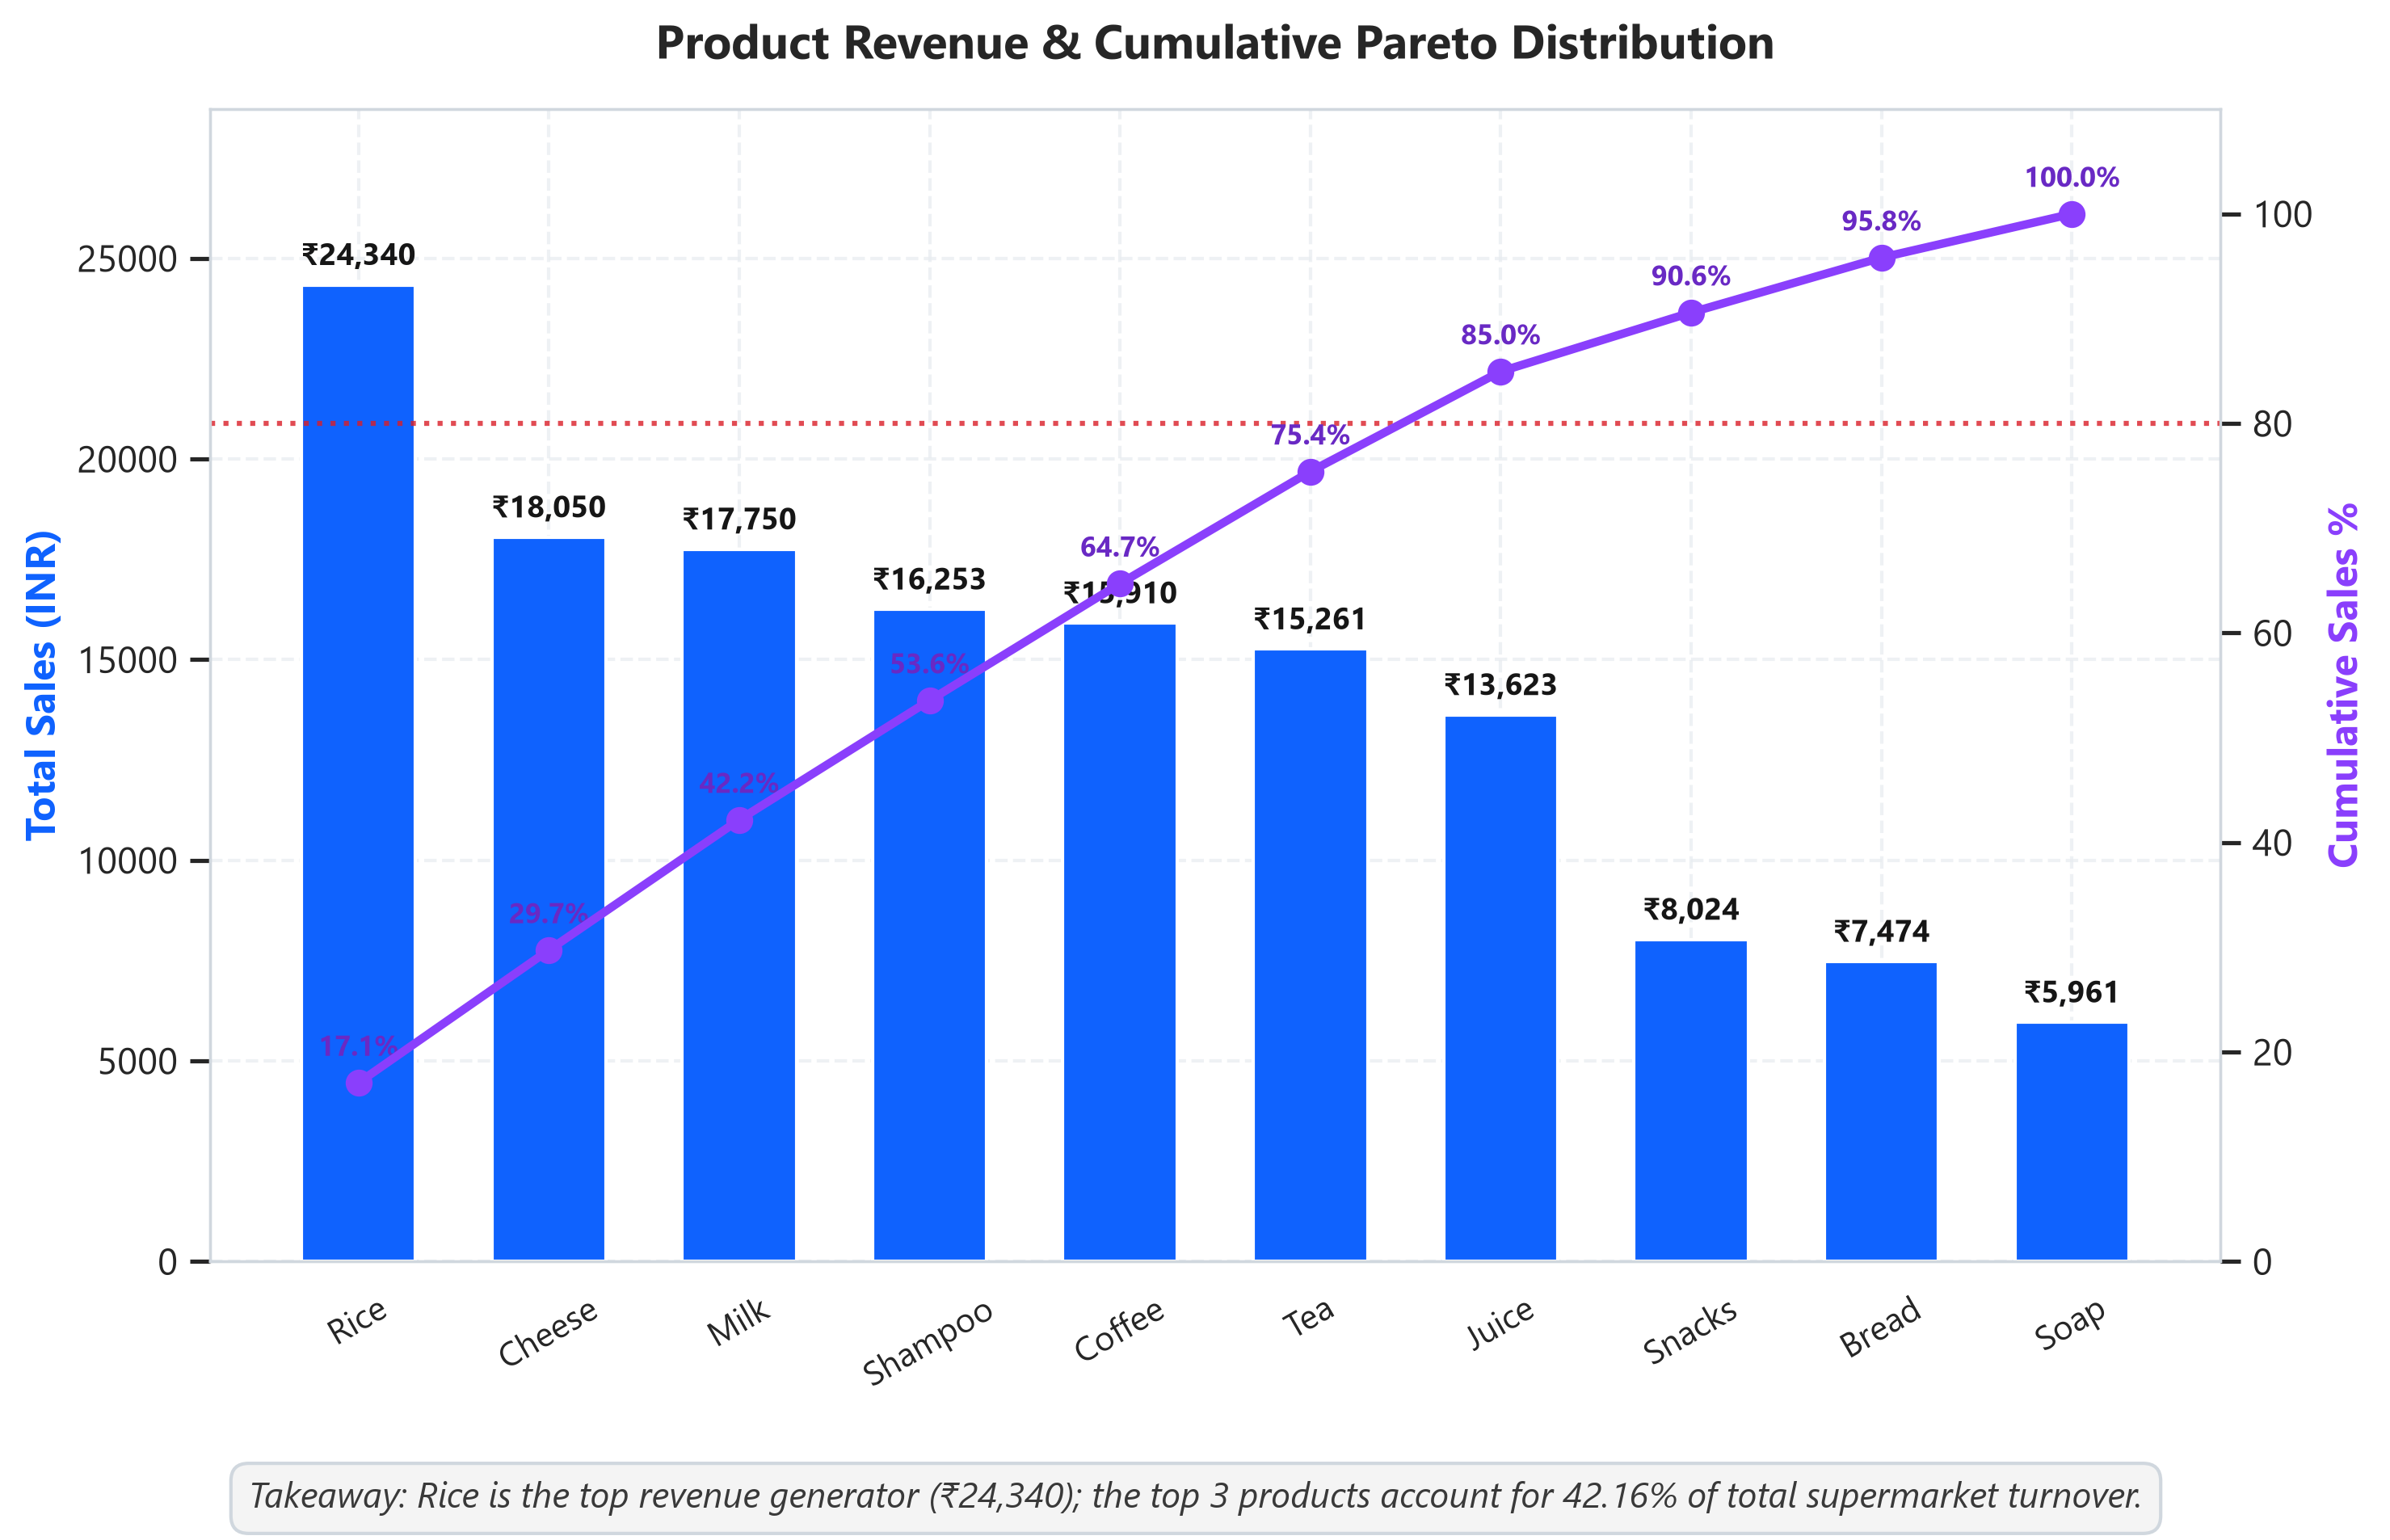

Displaying: 02_sales_by_branch_comparison.png


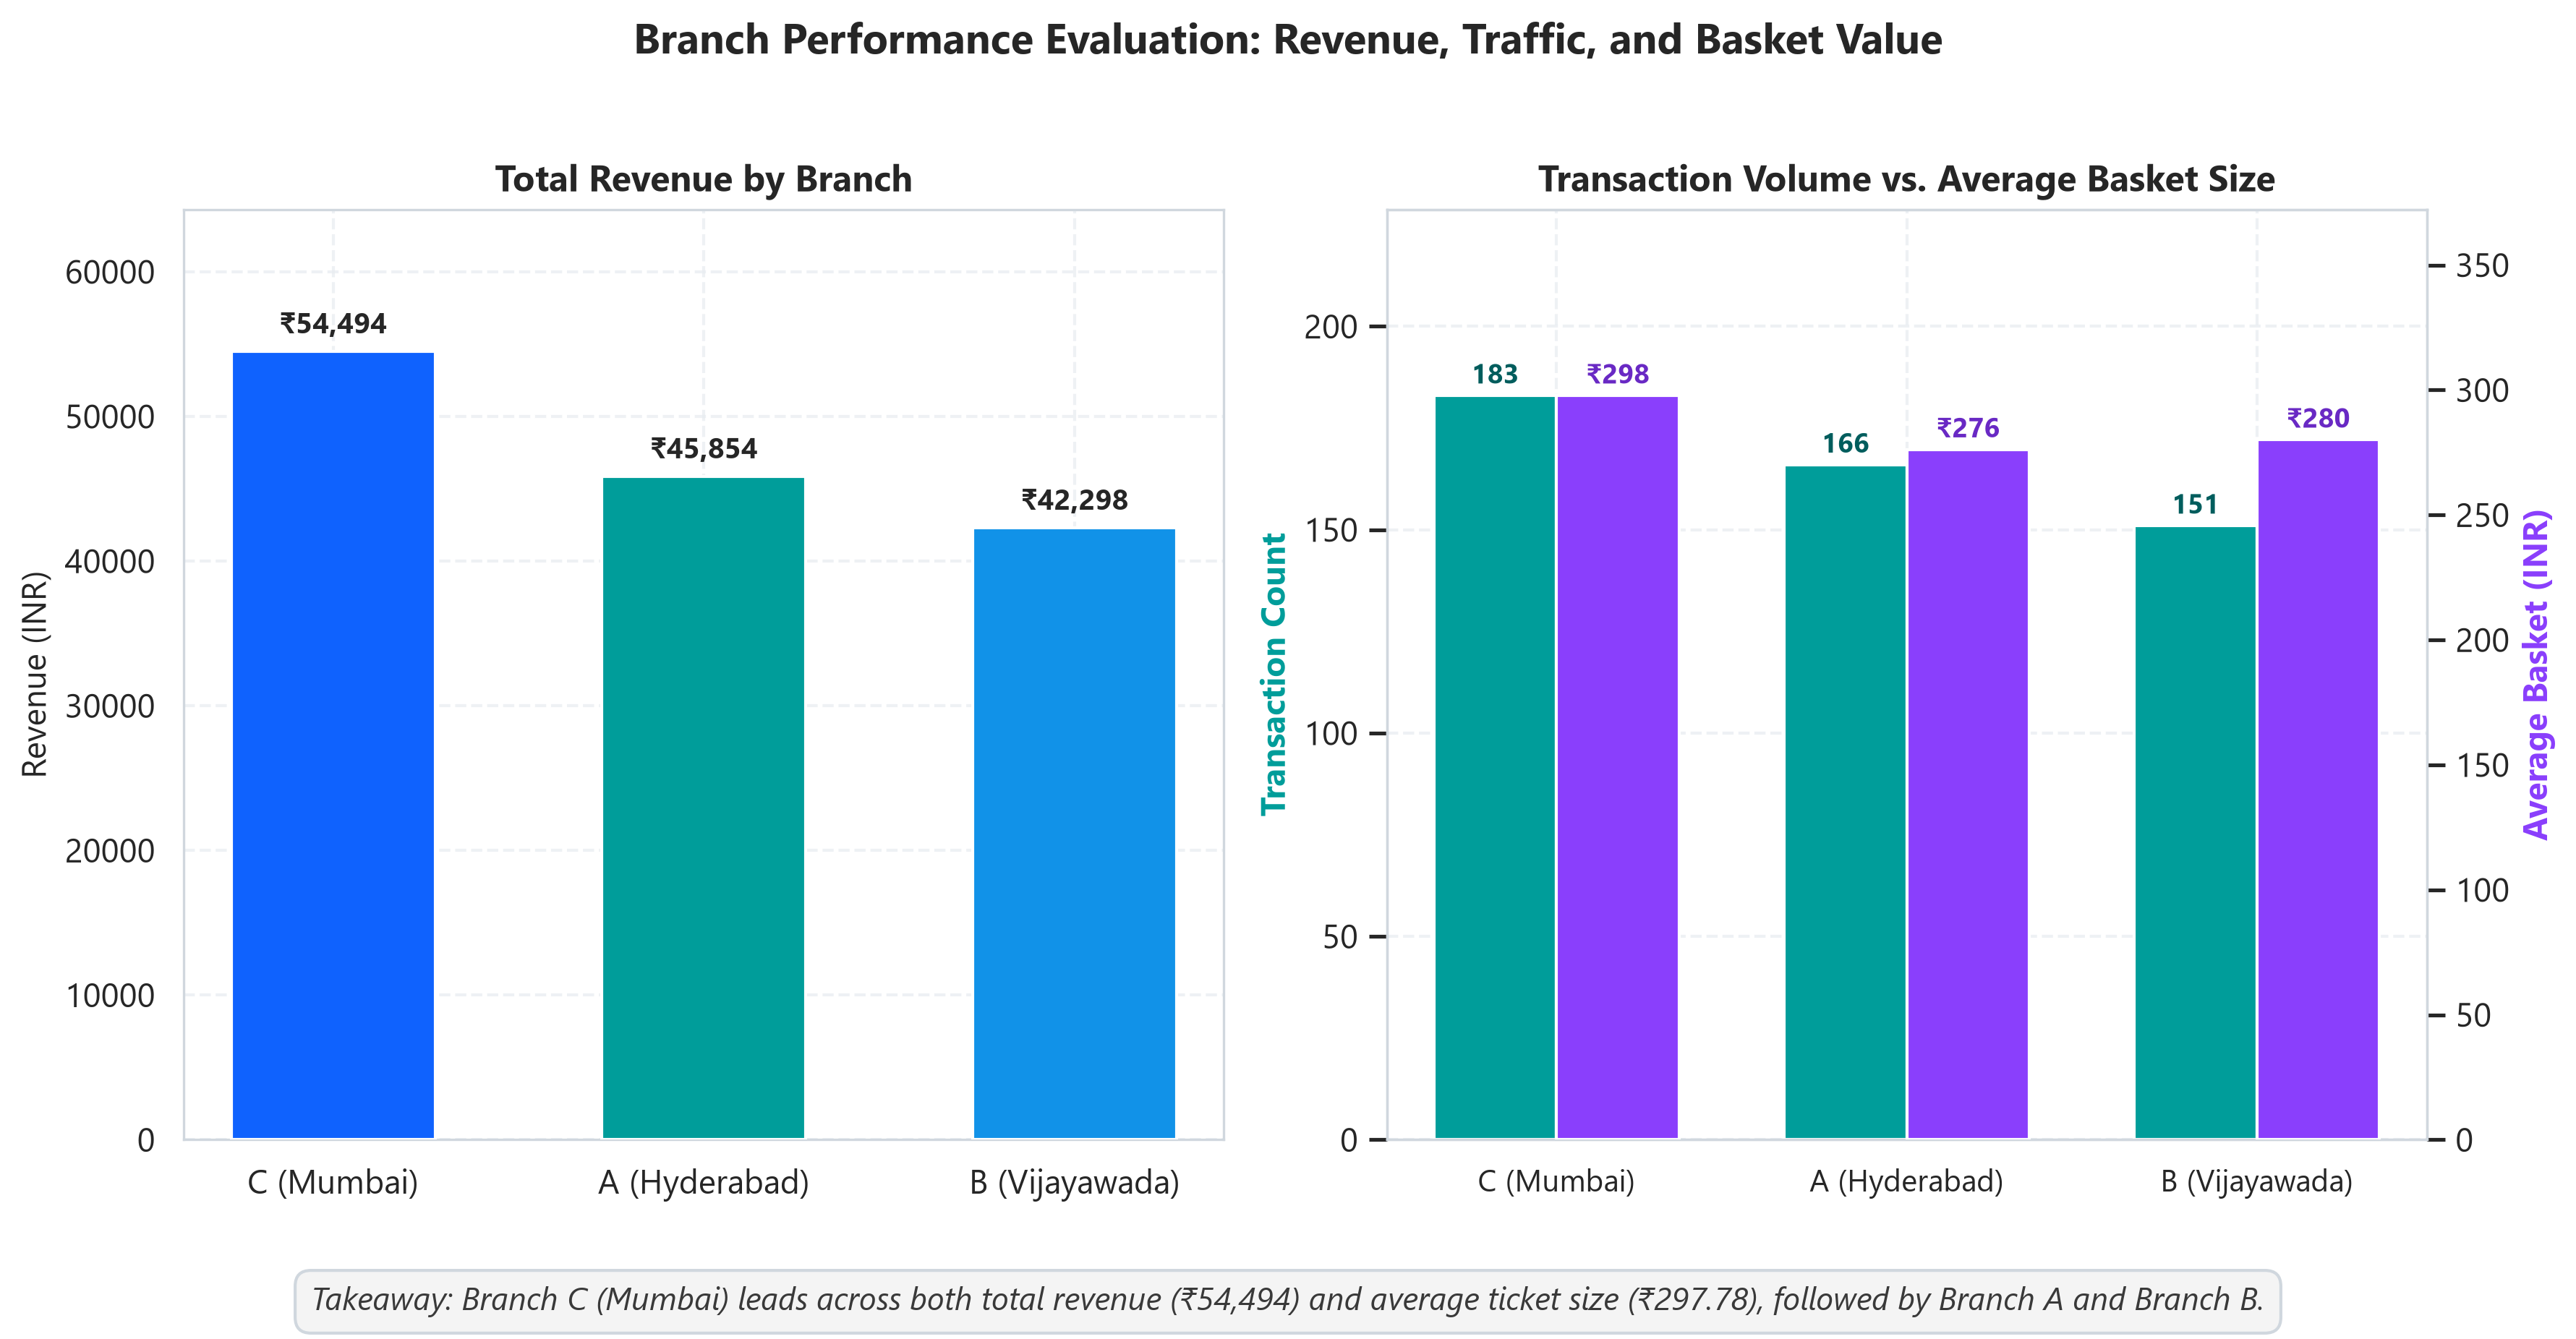

Displaying: 03_sales_by_category.png


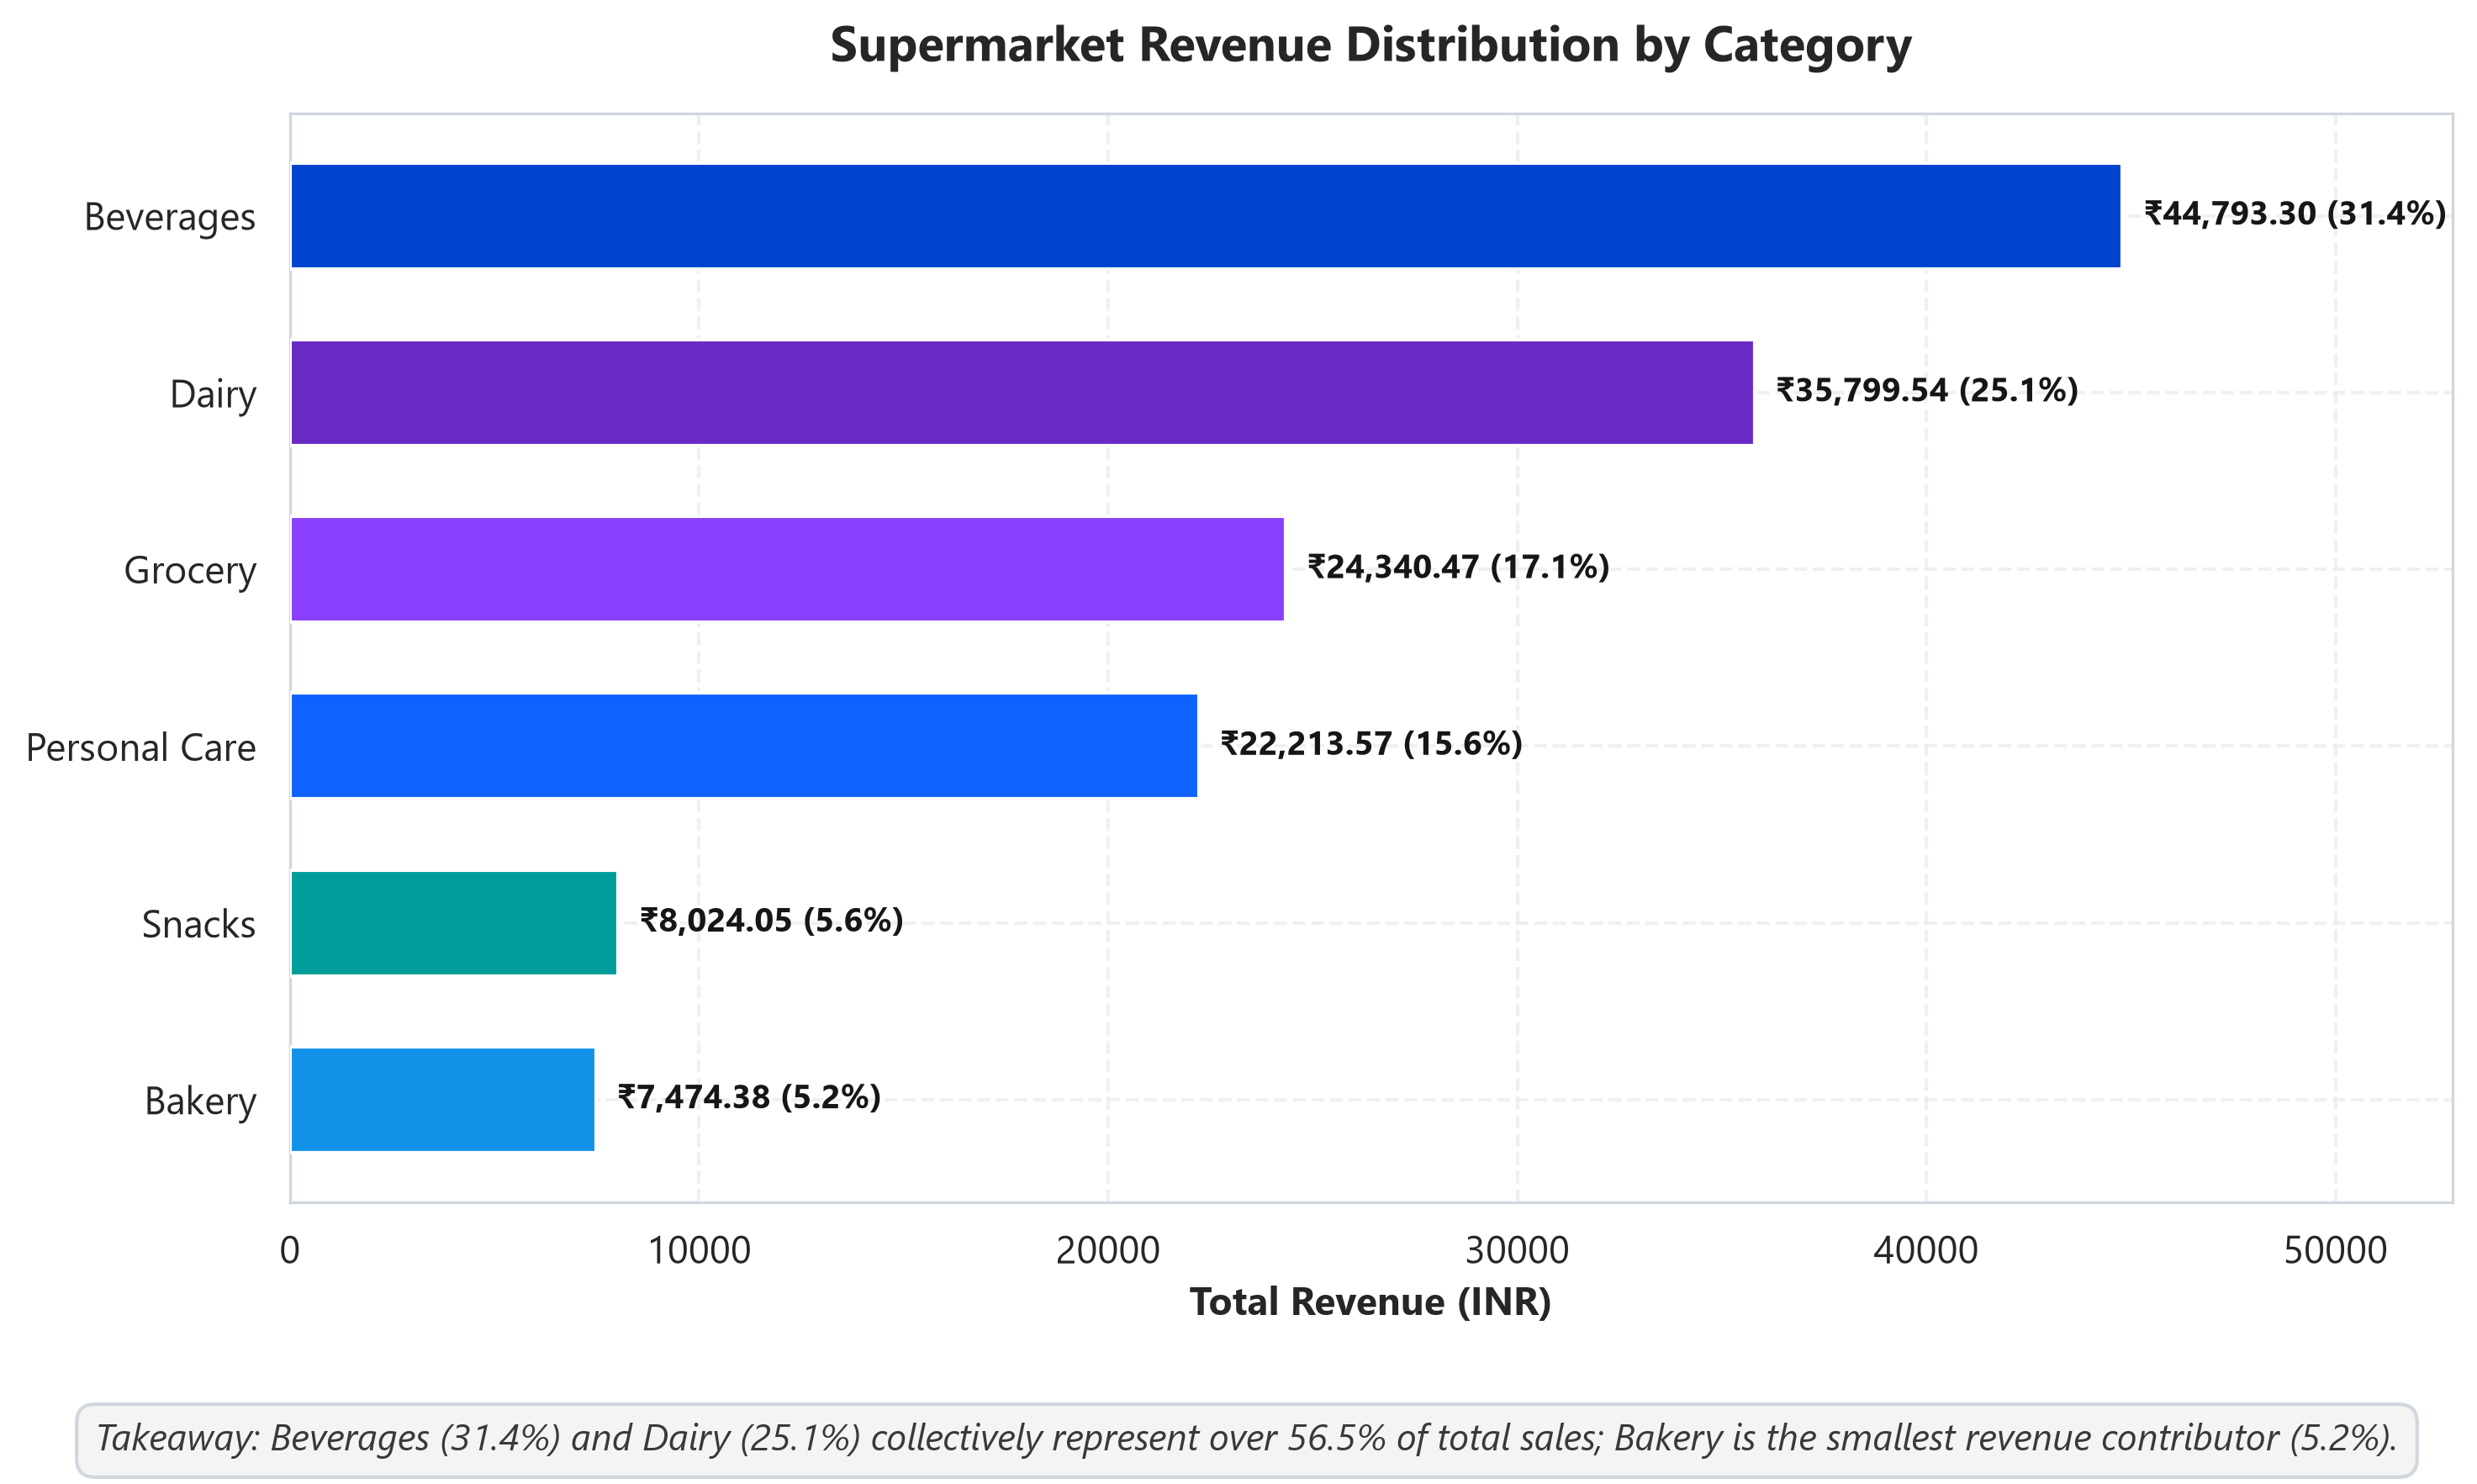

Displaying: 04_payment_methods_and_basket.png


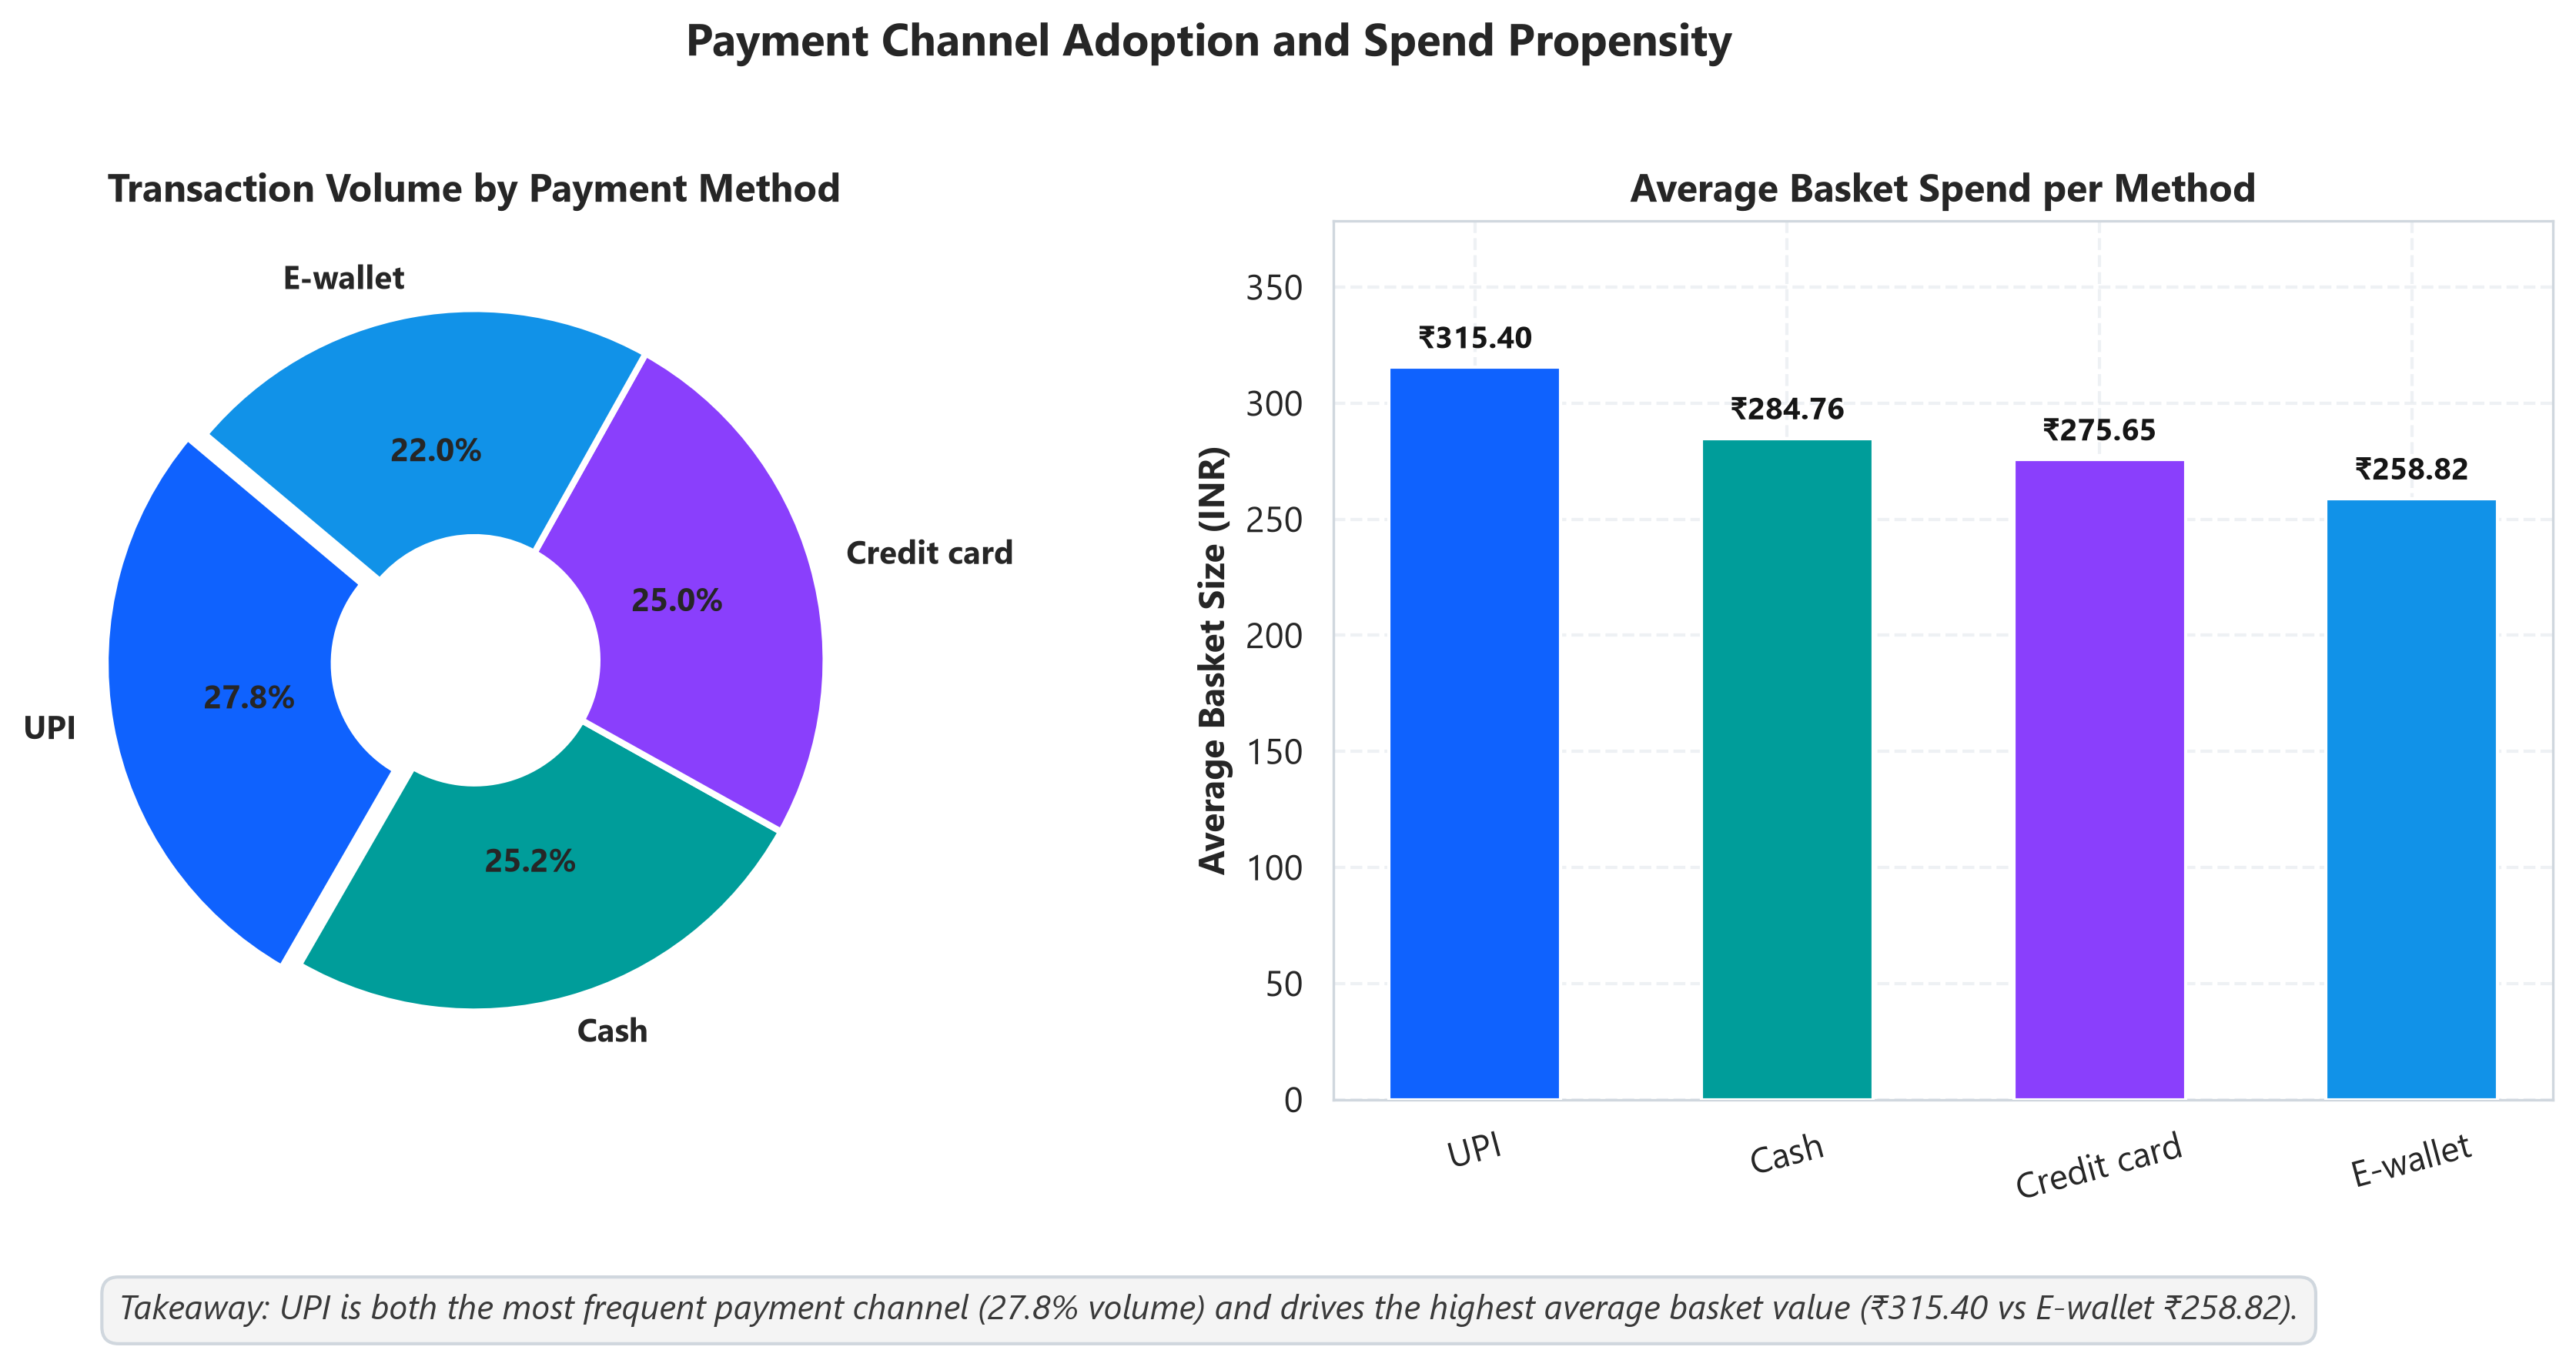

Displaying: 05_member_vs_normal_spend.png


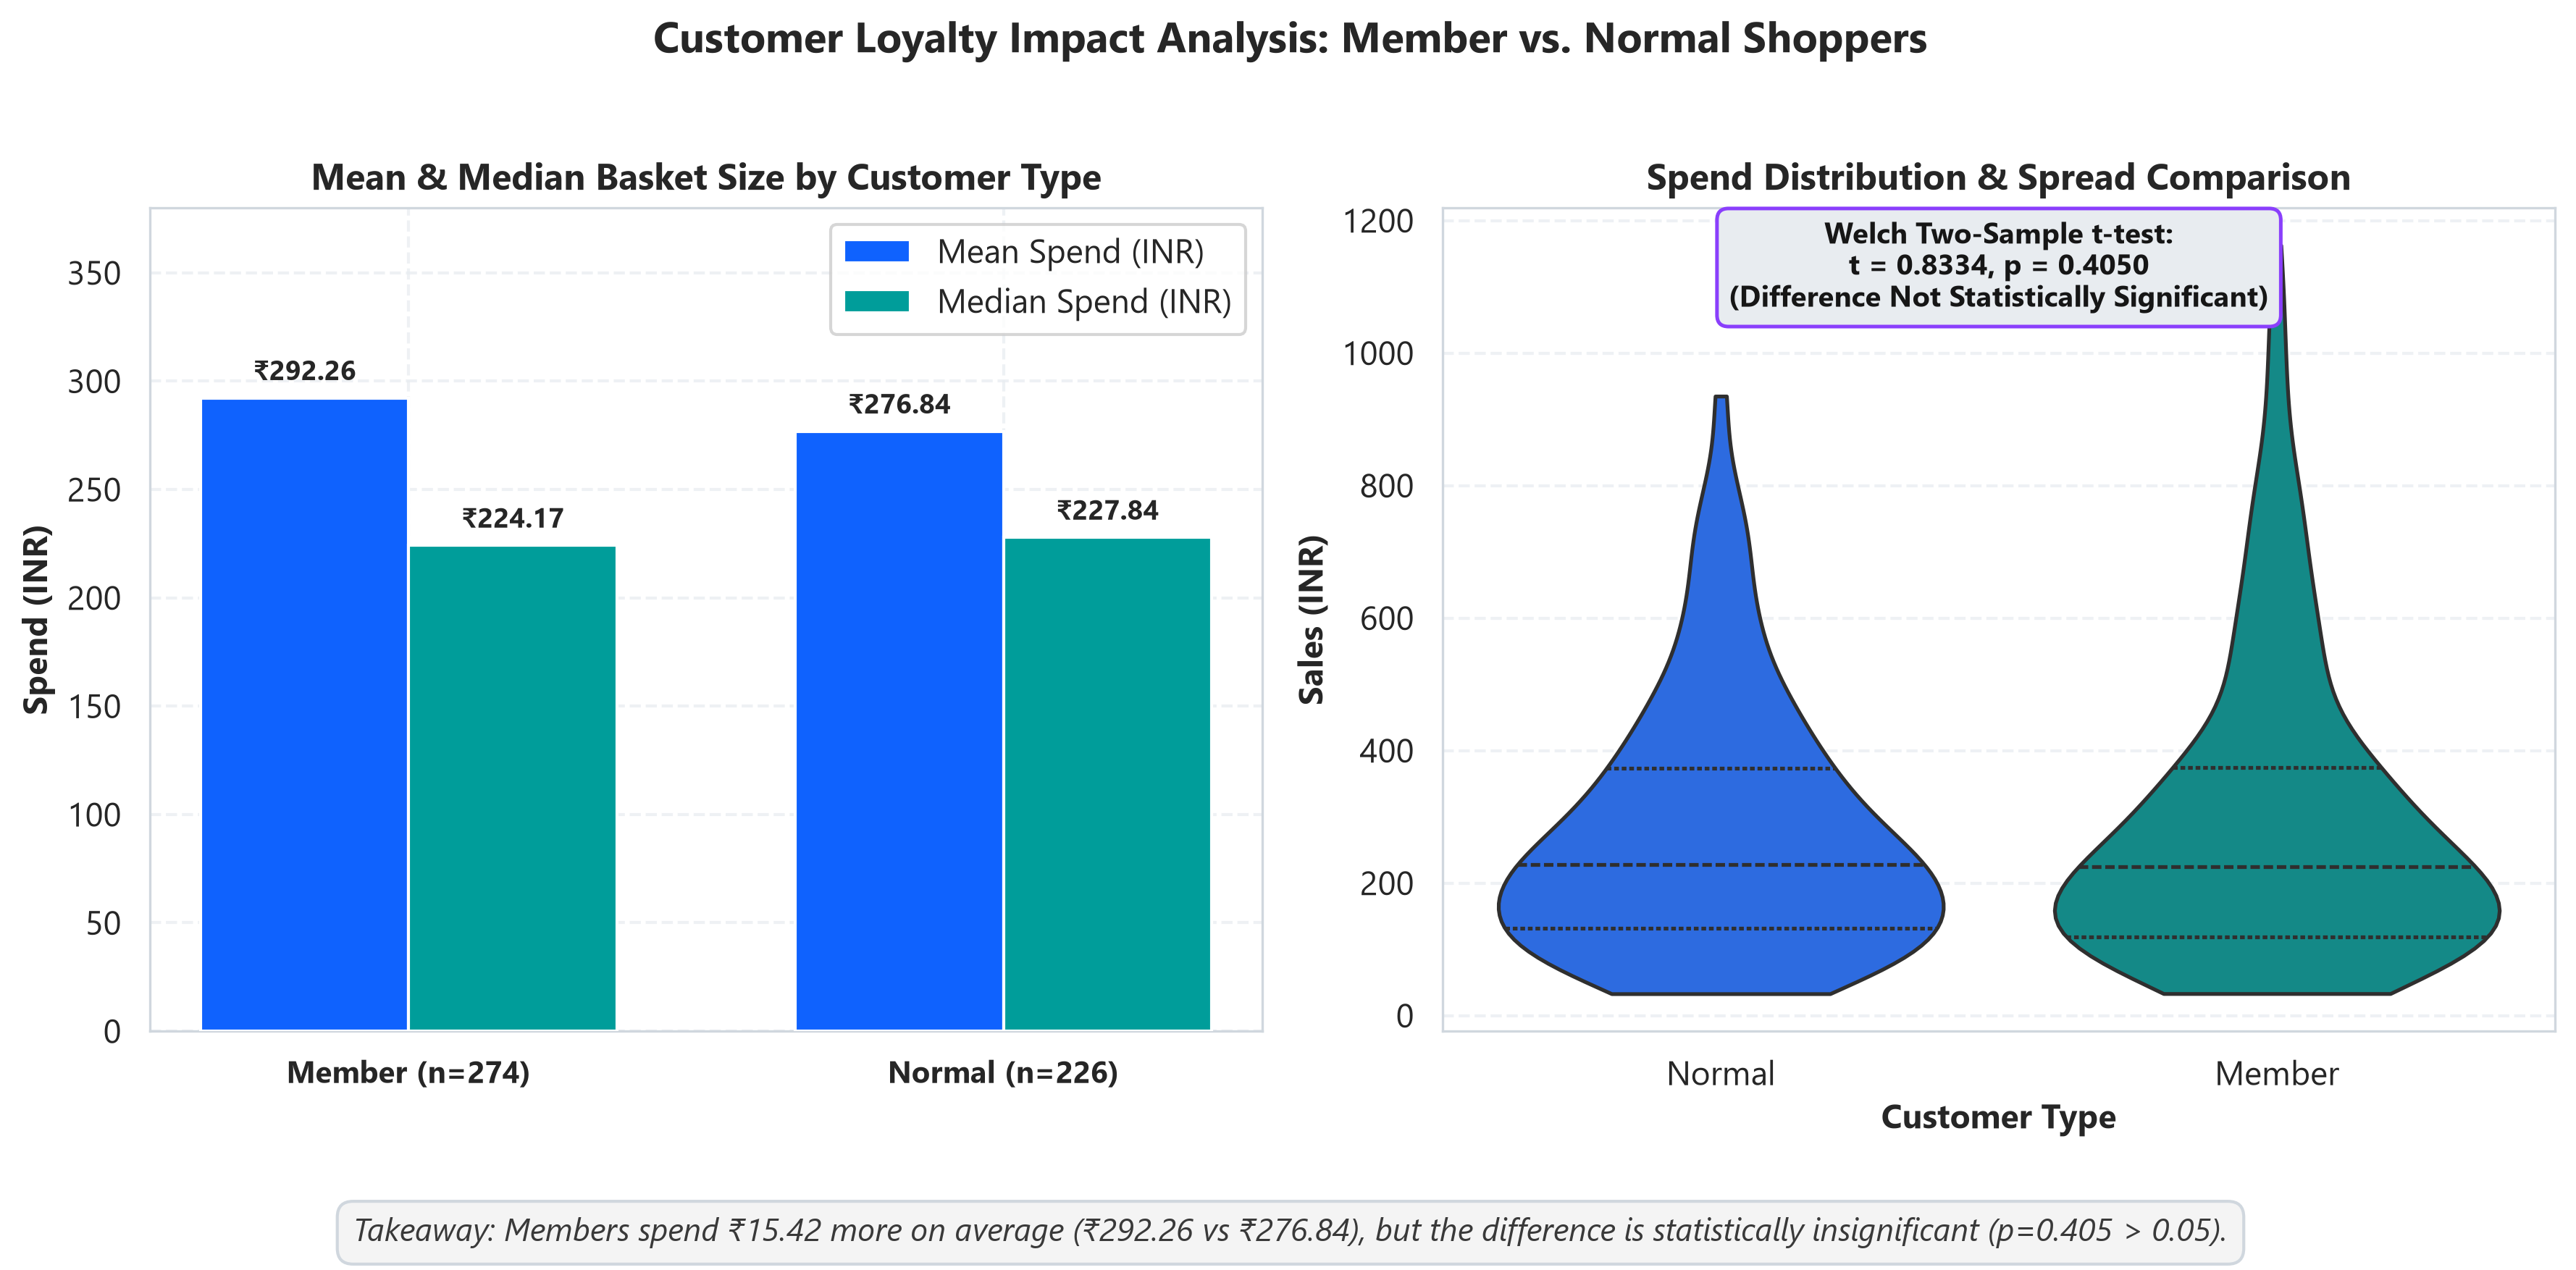

Displaying: 06_revenue_vs_units_top_bottom.png


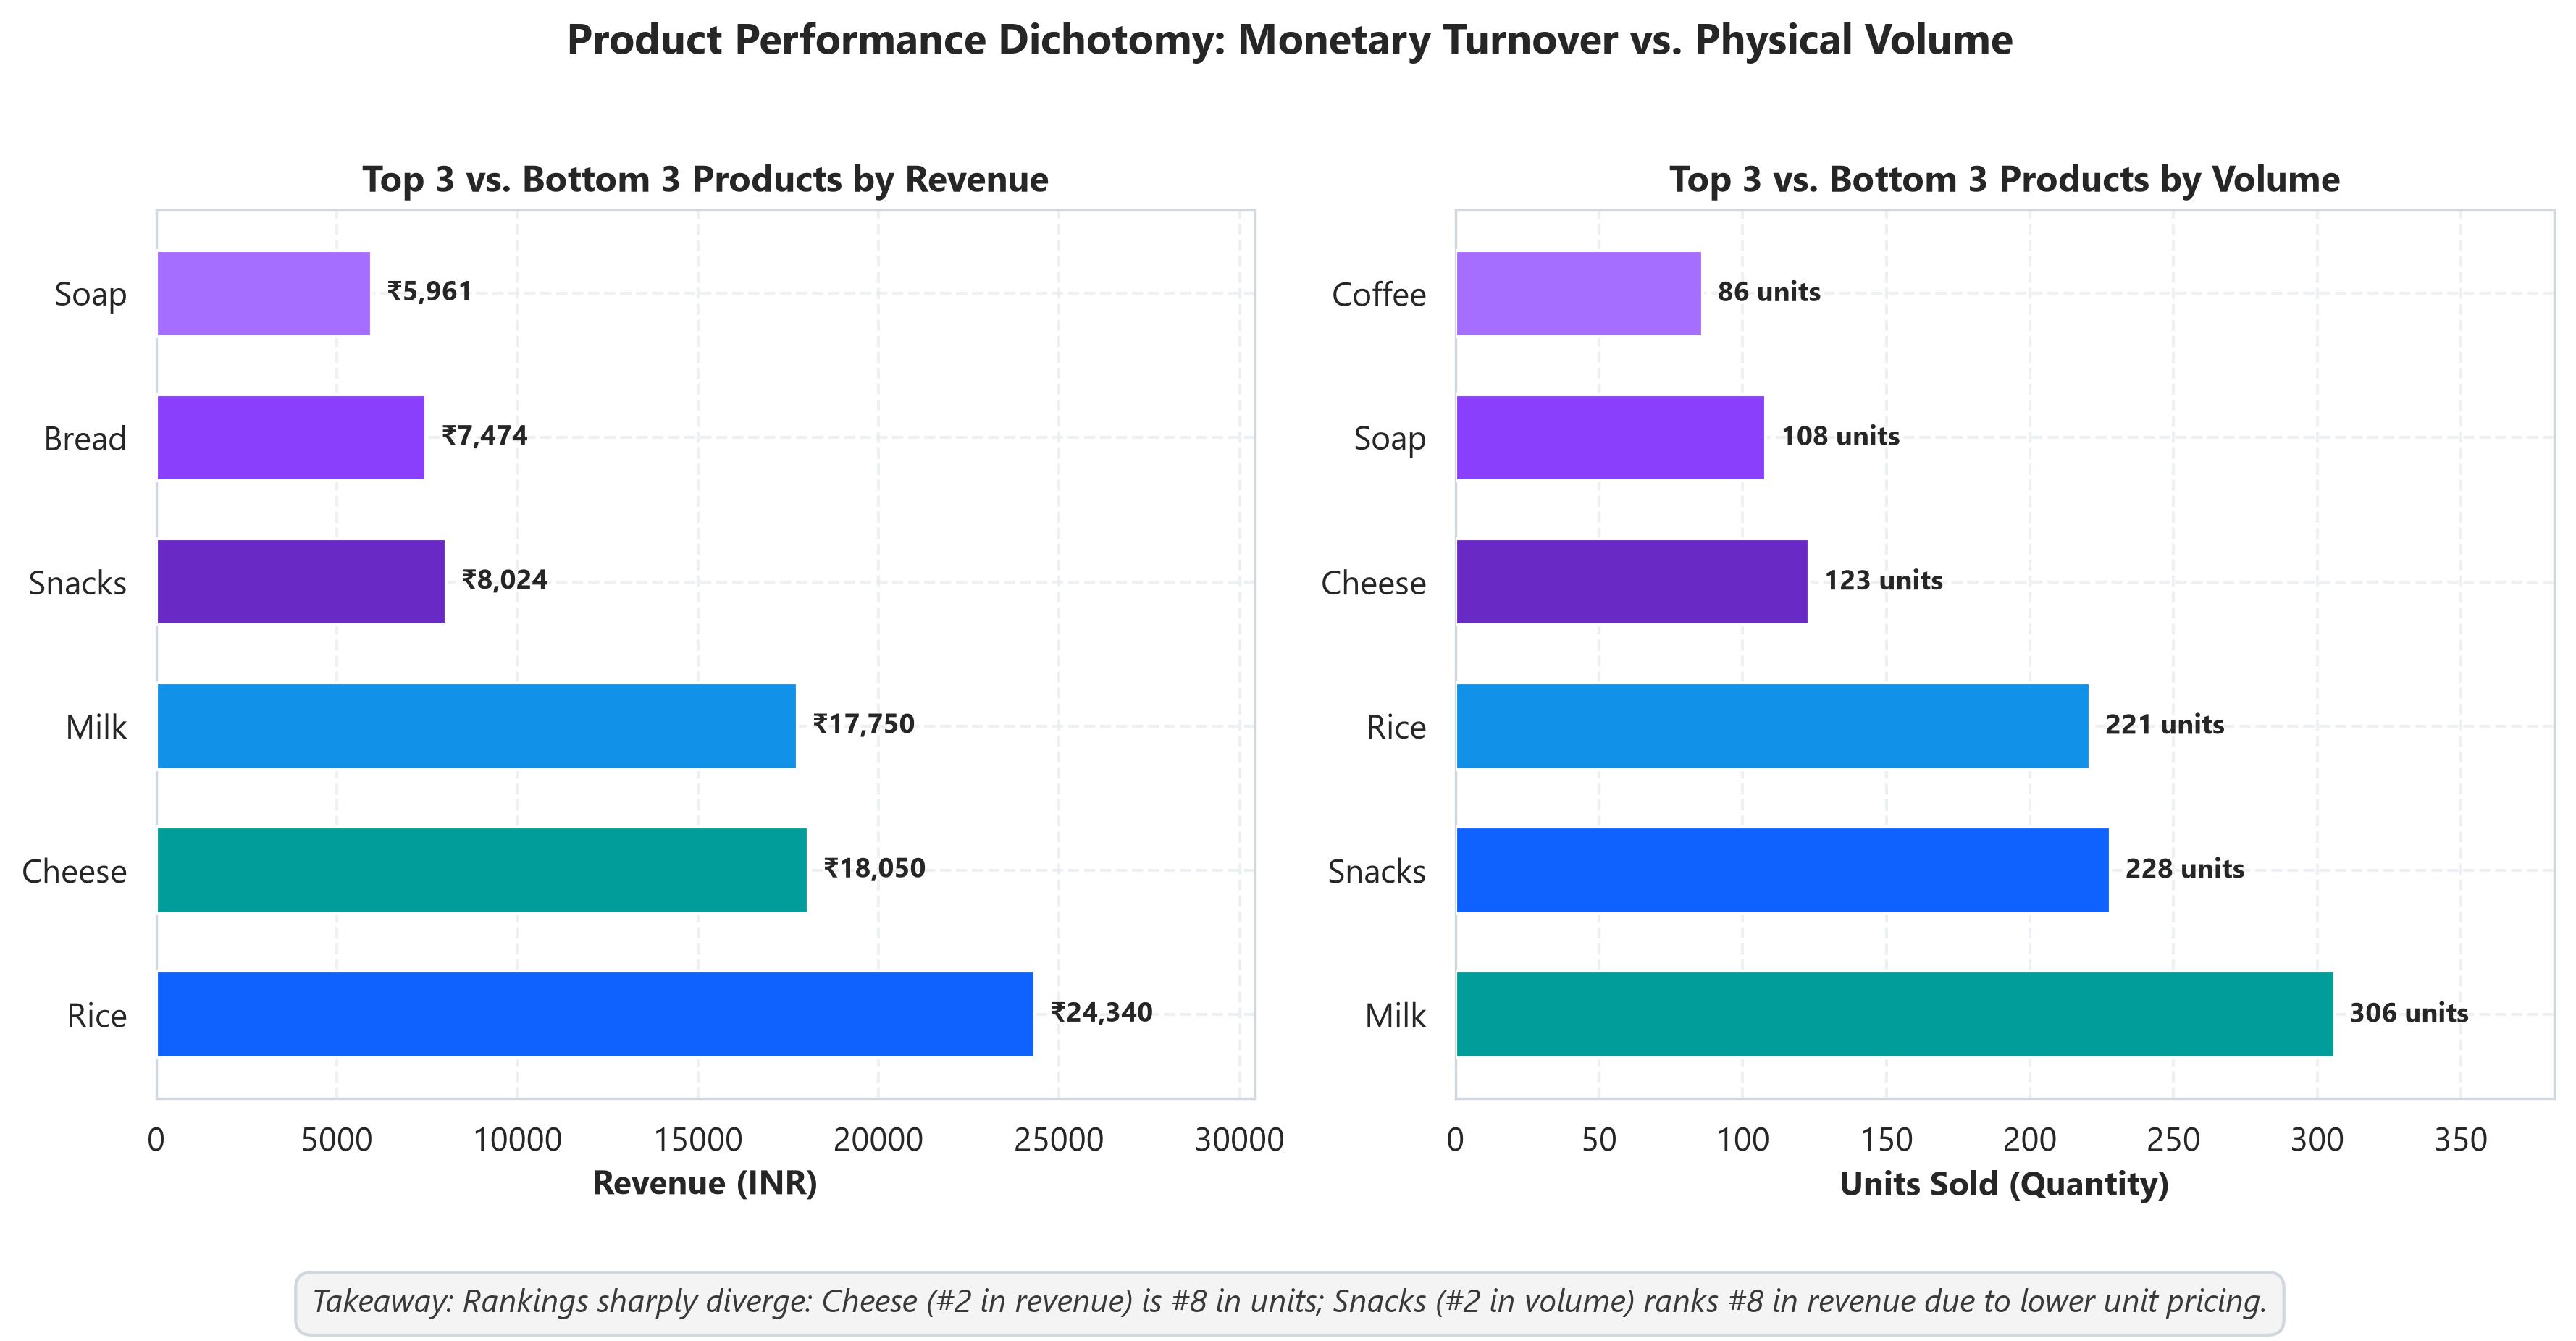

Displaying: 07_customer_category_heatmap.png


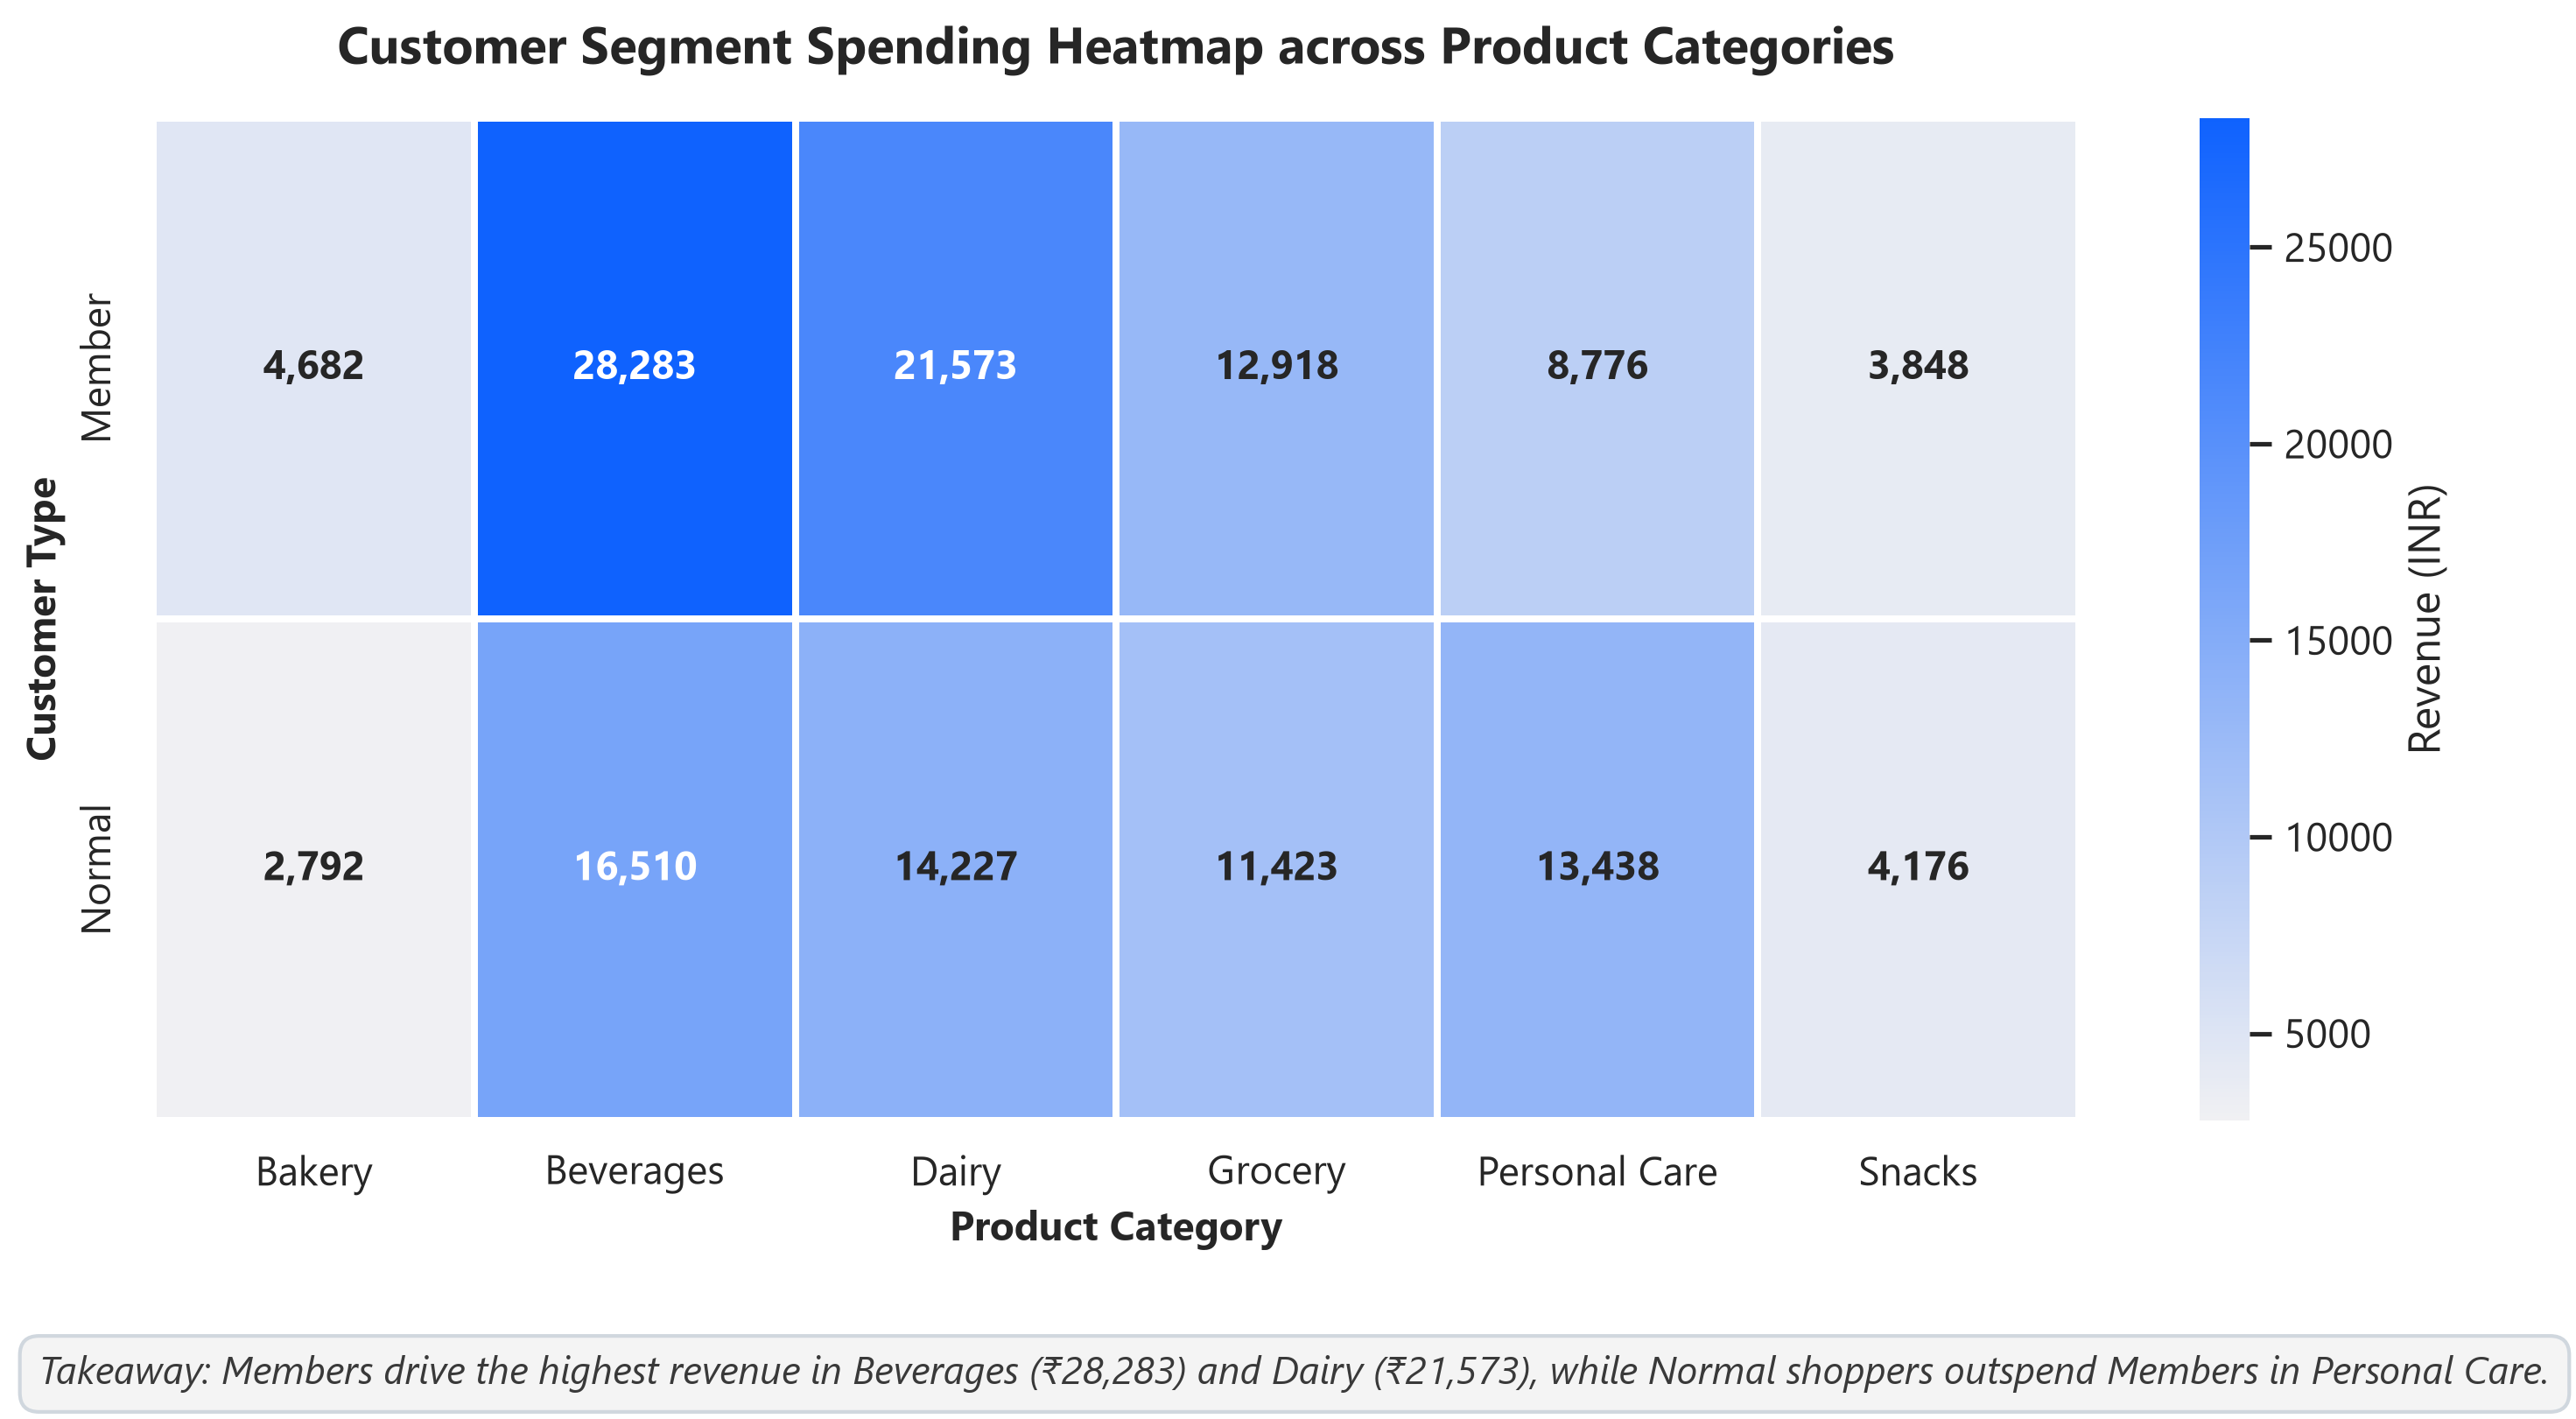

Displaying: 08_rating_vs_sales_correlation.png


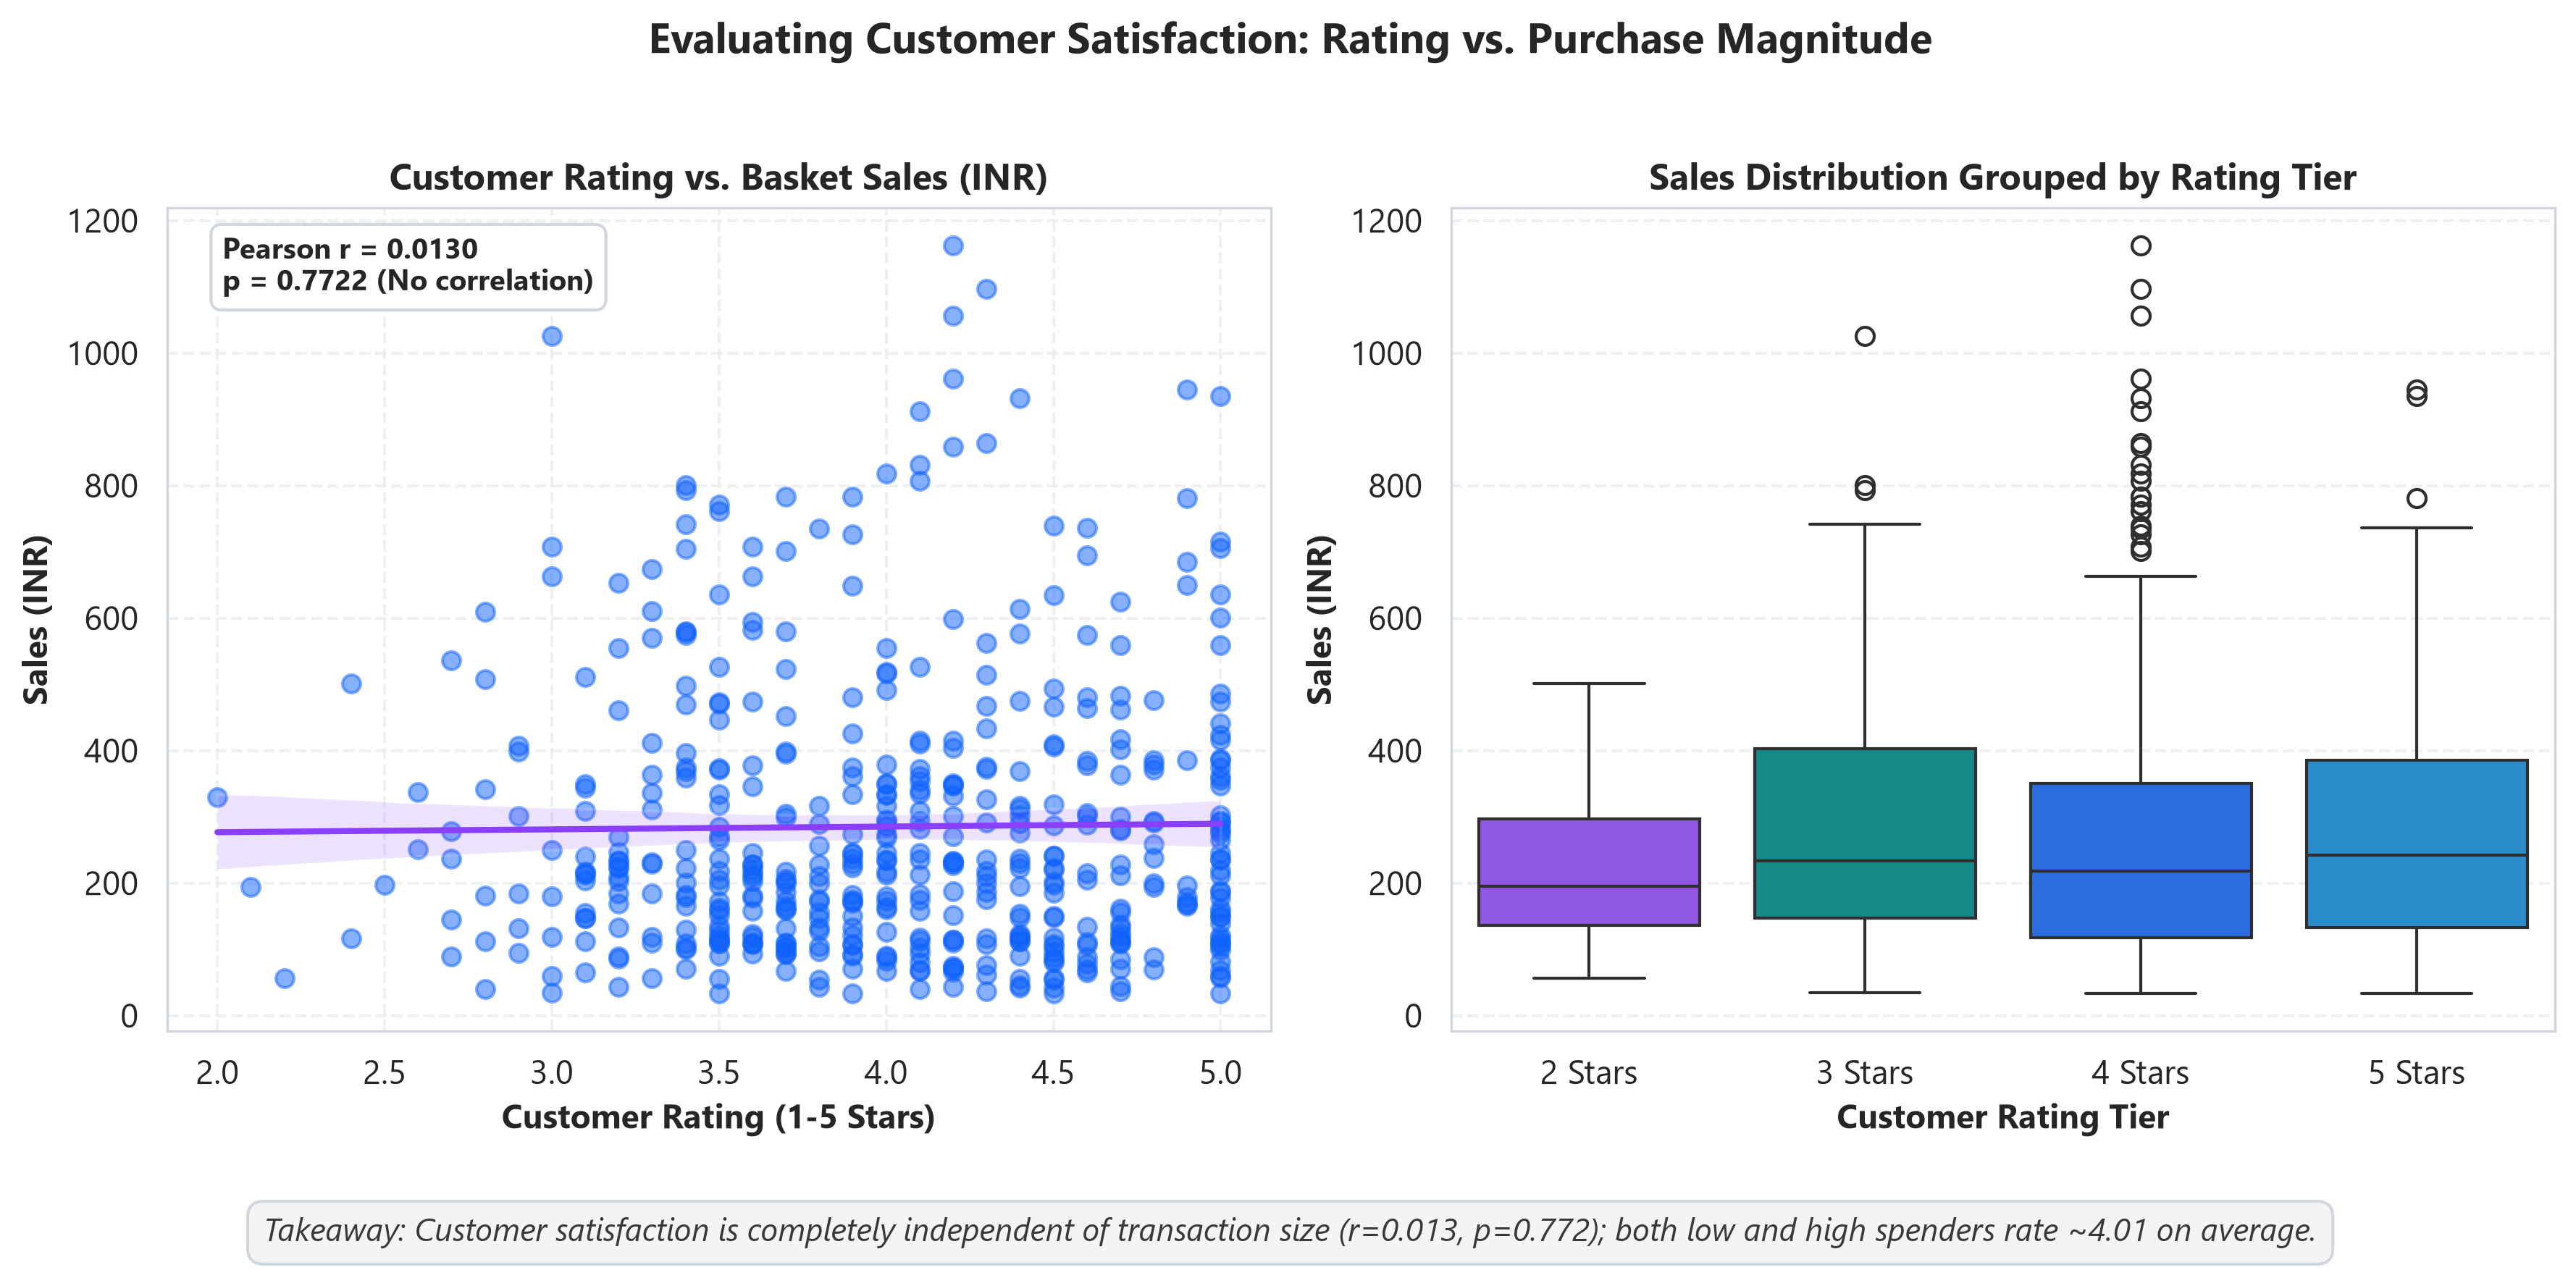

In [14]:
import os
from IPython.display import Image, display

chart_files = sorted([f for f in os.listdir('charts') if f.endswith('.png')])
print(f"Found {len(chart_files)} generated charts in /charts directory:\n")

for cf in chart_files:
    print(f"Displaying: {cf}")
    display(Image(filename=f"charts/{cf}", width=800))
